pct_A_grades — نسبة مواد الطالب اللي أخد فيها A



pct_below_C_grades — نسبة المواد الضعيفة



avg_grade_pts — متوسط grade points فعلي (أدق من GPA لأنه بيشيل الـ W)



quality_pts_total — إجمالي quality points المتراكمة



pct_retakes — نسبة المواد اللي اتعملت retake


summer_taken — هل الطالب بياخد summer terms


next_season — هل الترم الجاي Fall/Spring/Summer



In [1]:
!pip install scikit-learn pandas numpy joblib matplotlib seaborn --quiet


Imports

In [2]:
import json, os, glob
from datetime import datetime
from collections import defaultdict

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    GradientBoostingRegressor, GradientBoostingClassifier,
    RandomForestRegressor
)
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    mean_absolute_error, r2_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

print("All imports done!")



All imports done!


Upload & load JSON


In [3]:
from google.colab import files

uploaded = files.upload()
filename = list(uploaded.keys())[0]
print("Uploaded:", filename)

with open(filename) as f:
    data = json.load(f)

print(f"Students: {len(data)}")
print(f"Programs: {len(set(s['program'] for s in data))}")
print(f"Personas: {sorted(set(s.get('persona','') for s in data))}")



Saving transcripts.json to transcripts.json
Uploaded: transcripts.json
Students: 232
Programs: 16
Personas: ['average', 'disciplined_retake', 'high_achiever', 'honor_student', 'late_bloomer', 'part_time_worker', 'perfectionist', 'probation', 'solid_b', 'summer_intensive', 'transfer', 'withdrawal_heavy']


 Grade map

In [4]:
GRADE_MAP = {
    'A':   4.0, 'A-':  3.7,
    'B+':  3.3, 'B':   3.0, 'B-':  2.7,
    'C+':  2.3, 'C':   2.0, 'C-':  1.7,
    'D':   1.0, 'F':   0.0,
    '[A]':  4.0, '[A-]': 3.7,
    '[B+]': 3.3, '[B]':  3.0, '[B-]': 2.7,
    '[C+]': 2.3, '[C]':  2.0, '[C-]': 1.7,
    '[D]':  1.0,
}

def get_season(term_name):
    """Fall=0, Spring=1, Summer=2"""
    if 'Fall'   in term_name: return 0
    if 'Spring' in term_name: return 1
    if 'Summer' in term_name: return 2
    return -1


students.csv

In [5]:
rows = []
for student in data:
    sems = student['semesters']
    total_w = total_f = 0
    term_gpas = []

    for sem in sems:
        tg = sem['term_statistics']['term_gpa']
        if tg is not None:
            term_gpas.append(tg)
        for c in sem['courses']:
            if c['grade'] == 'W': total_w += 1
            if c['grade'] == 'F': total_f += 1

    first_gpa = sems[0]['term_statistics']['term_gpa'] or 0.0
    last_gpa  = sems[-1]['term_statistics']['term_gpa'] or 0.0
    avg_gpa   = round(sum(term_gpas)/len(term_gpas), 4) if term_gpas else 0.0

    rows.append({
        'student_id':        student['student_id'],
        'program':           student['program'],
        'gender':            student['gender'],
        'persona':           student.get('persona',''),
        'entry_year':        student['entry_year'],
        'enrollment_status': student['enrollment_status'],
        'cumulative_gpa':    student['cumulative_gpa'],
        'num_semesters':     len(sems),
        'total_credits':     sems[-1]['running_totals']['attempted_credits'],
        'total_withdrawals': total_w,
        'total_failures':    total_f,
        'first_term_gpa':    first_gpa,
        'last_term_gpa':     last_gpa,
        'avg_term_gpa':      avg_gpa,
        'gpa_trend':         round(last_gpa - first_gpa, 4),
        'is_on_probation':   1 if student['enrollment_status'] == 'Academic Probation' else 0,
    })

df_students = pd.DataFrame(rows)
df_students.to_csv('students.csv', index=False)
print(f"students.csv — {len(df_students)} rows")


students.csv — 232 rows


courses.csv


In [6]:
course_rows = []
for student in data:
    for sem_idx, sem in enumerate(student['semesters']):
        for c in sem['courses']:
            g = c['grade']
            course_rows.append({
                'student_id':    student['student_id'],
                'program':       student['program'],
                'persona':       student.get('persona',''),
                'gender':        student['gender'],
                'entry_year':    student['entry_year'],
                'semester_index':sem_idx,
                'term_name':     sem['term_name'],
                'season':        get_season(sem['term_name']),
                'term_gpa':      sem['term_statistics']['term_gpa'],
                'cumgpa_at_term':sem['running_totals']['cumulative_gpa'],
                'course_id':     c['course_id'],
                'course_title':  c['title'],
                'subtype':       c.get('subtype',''),
                'credits':       c['credits'],
                'grade':         g,
                'grade_points':  GRADE_MAP.get(g, None),
                'quality_points':c.get('quality_points', 0),
                'is_withdrawal': 1 if g == 'W'          else 0,
                'is_fail':       1 if g == 'F'          else 0,
                'is_retake':     1 if g.startswith('[') else 0,
                'is_lab':        1 if c.get('subtype') == 'LAB' else 0,
            })

df_courses = pd.DataFrame(course_rows)
df_courses.to_csv('courses.csv', index=False)
print(f"courses.csv — {len(df_courses)} rows")


courses.csv — 8441 rows


In [7]:
files.download('students.csv')
files.download('courses.csv')
print("Check Downloads!")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Check Downloads!


Training Snapshots

In [8]:
snapshot_rows = []

for student in data:
    sems       = student['semesters']
    program    = student['program']
    gender     = student['gender']
    persona    = student.get('persona', '')
    entry_year = student['entry_year']
    is_transfer = 1 if persona == 'transfer' else 0

    if len(sems) < 2:
        continue

    all_term_gpas = [s['term_statistics']['term_gpa'] for s in sems]

    w_count = f_count = retake_count = lab_count = 0
    total_courses = 0
    quality_pts_total = 0.0
    grade_pts_all = []
    summer_taken = 0

    for n in range(len(sems)):
        sem = sems[n]

        if 'Summer' in sem['term_name']:
            summer_taken = 1

        for c in sem['courses']:
            g = c['grade']
            total_courses += 1
            quality_pts_total += c.get('quality_points', 0) or 0
            if g == 'W': w_count += 1
            if g == 'F': f_count += 1
            if g.startswith('['): retake_count += 1
            if c.get('subtype') == 'LAB': lab_count += 1
            gp = GRADE_MAP.get(g)
            if gp is not None:
                grade_pts_all.append(gp)

        if n == 0:
            continue

        target_gpa = all_term_gpas[n]
        if target_gpa is None:
            continue

        # GPAs
        raw_prev   = all_term_gpas[:n]
        valid_prev = [g for g in raw_prev if g is not None]
        if not valid_prev:
            continue

        # GPA features
        last_gpa        = valid_prev[-1]
        avg_gpa         = round(sum(valid_prev) / len(valid_prev), 4)
        min_gpa         = min(valid_prev)
        max_gpa         = max(valid_prev)
        gpa_std         = round(float(pd.Series(valid_prev).std(ddof=0)) if len(valid_prev) > 1 else 0.0, 4)
        gpa_trend       = round(valid_prev[-1] - valid_prev[0], 4) if len(valid_prev) >= 2 else 0.0
        recent_trend    = round(valid_prev[-1] - valid_prev[-2], 4) if len(valid_prev) >= 2 else 0.0
        terms_below_2   = sum(1 for g in valid_prev if g < 2.0)
        terms_below_25  = sum(1 for g in valid_prev if g < 2.5)
        is_recovering   = 1 if (len(valid_prev) >= 2 and valid_prev[-1] > valid_prev[-2]) else 0

        # Course-level features
        pct_A      = sum(1 for g in grade_pts_all if g >= 3.7) / len(grade_pts_all) if grade_pts_all else 0.0
        pct_B_plus = sum(1 for g in grade_pts_all if g >= 3.3) / len(grade_pts_all) if grade_pts_all else 0.0
        pct_below_C= sum(1 for g in grade_pts_all if g < 2.0) / len(grade_pts_all) if grade_pts_all else 0.0
        pct_retake = retake_count / total_courses if total_courses else 0.0
        pct_lab    = lab_count    / total_courses if total_courses else 0.0
        avg_grade_pts = sum(grade_pts_all) / len(grade_pts_all) if grade_pts_all else 0.0

        # Season feature
        next_season = get_season(sems[n]['term_name'])

        snapshot_rows.append({
            #Student info
            'program':            program,
            'gender':             gender,
            'persona':            persona,
            'entry_year':         entry_year,
            'is_transfer':        is_transfer,

            # GPA history
            'semester_number':    n,
            'cumgpa_before':      sems[n-1]['running_totals']['cumulative_gpa'],
            'last_term_gpa':      last_gpa,
            'avg_gpa_so_far':     avg_gpa,
            'min_gpa':            min_gpa,
            'max_gpa':            max_gpa,
            'gpa_std':            gpa_std,
            'gpa_trend':          gpa_trend,
            'recent_trend':       recent_trend,
            'terms_below_2':      terms_below_2,
            'terms_below_25':     terms_below_25,
            'is_recovering':      is_recovering,

            #Counts
            'credits_so_far':     sems[n-1]['running_totals']['attempted_credits'],
            'withdrawals_so_far': w_count,
            'failures_so_far':    f_count,

            # Course-level (جديد)
            'pct_A_grades':       round(pct_A, 4),
            'pct_B_plus_grades':  round(pct_B_plus, 4),
            'pct_below_C_grades': round(pct_below_C, 4),
            'pct_retakes':        round(pct_retake, 4),
            'pct_lab_courses':    round(pct_lab, 4),
            'avg_grade_pts':      round(avg_grade_pts, 4),
            'quality_pts_total':  round(quality_pts_total, 2),
            'summer_taken':       summer_taken,
            'next_season':        next_season,

            #Targetس
            'target_gpa':         target_gpa,
            'target_at_risk':     1 if target_gpa < 2.0 else 0,
        })

df_snap = pd.DataFrame(snapshot_rows)
print(f"Training snapshots: {len(df_snap)}")
print(f"At-risk rate: {round(df_snap['target_at_risk'].mean() * 100, 1)}%")
df_snap.head(3)



Training snapshots: 1086
At-risk rate: 13.0%


,program,gender,persona,entry_year,is_transfer,semester_number,cumgpa_before,last_term_gpa,avg_gpa_so_far,min_gpa,...,pct_B_plus_grades,pct_below_C_grades,pct_retakes,pct_lab_courses,avg_grade_pts,quality_pts_total,summer_taken,next_season,target_gpa,target_at_risk
0,Biomedical Sciences,Female,high_achiever,2022,0,1,3.9471,3.9471,3.9471,3.9471,...,1.0,0.0,0.0,0.0,3.8875,134.2,0,1,3.9471,0
1,Biomedical Sciences,Female,high_achiever,2022,0,2,3.9471,3.9471,3.9471,3.9471,...,1.0,0.0,0.0,0.0,3.8875,213.3,0,0,3.9550,0
2,Biomedical Sciences,Female,high_achiever,2022,0,3,3.9500,3.9550,3.9497,3.9471,...,1.0,0.0,0.0,0.0,3.8900,276.7,0,1,3.9625,0


EDA

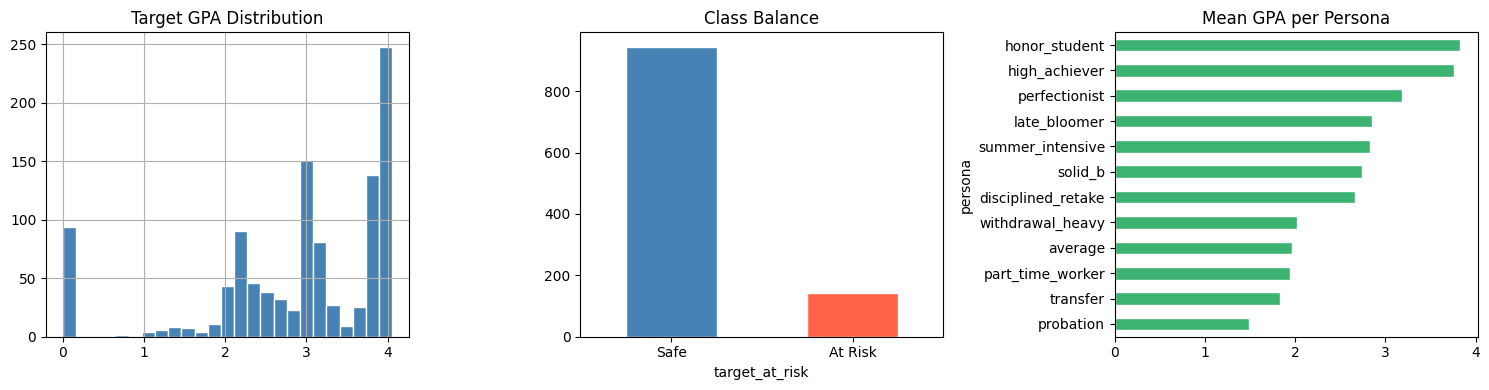

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df_snap['target_gpa'].hist(bins=25, ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Target GPA Distribution')

df_snap['target_at_risk'].value_counts().plot(
    kind='bar', ax=axes[1], color=['steelblue','tomato'], edgecolor='white')
axes[1].set_xticklabels(['Safe','At Risk'], rotation=0)
axes[1].set_title('Class Balance')

# persona vs GPA
persona_avg = df_snap.groupby('persona')['target_gpa'].mean().sort_values()
persona_avg.plot(kind='barh', ax=axes[2], color='mediumseagreen', edgecolor='white')
axes[2].set_title('Mean GPA per Persona')

plt.tight_layout()
plt.show()

ncoding + Feature Selection

In [13]:
le_gender  = LabelEncoder()
le_persona = LabelEncoder()

df_snap['gender_enc']  = le_gender.fit_transform(df_snap['gender'])
df_snap['persona_enc'] = le_persona.fit_transform(df_snap['persona'])

program_mean_gpa = df_snap.groupby('program')['target_gpa'].mean()
persona_mean_gpa = df_snap.groupby('persona')['target_gpa'].mean()

df_snap['program_target_enc'] = df_snap['program'].map(program_mean_gpa)
df_snap['persona_target_enc'] = df_snap['persona'].map(persona_mean_gpa)



In [14]:
FEATURES = [
    # GPA history — أقوى group
    'cumgpa_before',
    'max_gpa',
    'avg_gpa_so_far',
    'avg_grade_pts',
    'last_term_gpa',
    'min_gpa',
    'quality_pts_total',

    # Risk indicators
    'failures_so_far',
    'terms_below_25',
    'terms_below_2',
    'pct_below_C_grades',
    'withdrawals_so_far',
    'pct_retakes',

    # Achievement indicators
    'pct_A_grades',
    'pct_B_plus_grades',
    'is_recovering',

    # Student profile
    'persona_target_enc',
    'persona_enc',
    'program_target_enc',
    'entry_year',
    'is_transfer',
    'summer_taken',
    'next_season',
]

X      = df_snap[FEATURES]
y_gpa  = df_snap['target_gpa']
y_risk = df_snap['target_at_risk']

print(f"Features: {len(FEATURES)}")
print(f"Shape: {X.shape}")


Features: 23
Shape: (1086, 23)


In [15]:
print("\nTop correlations with target_gpa:")
corr = df_snap[FEATURES + ['target_gpa']].corr()['target_gpa'].drop('target_gpa')
print(corr.abs().sort_values(ascending=False).round(3).to_string())




Top correlations with target_gpa:
persona_target_enc    0.663
avg_grade_pts         0.648
cumgpa_before         0.644
max_gpa               0.638
pct_B_plus_grades     0.627
pct_A_grades          0.588
avg_gpa_so_far        0.583
pct_below_C_grades    0.462
next_season           0.429
failures_so_far       0.428
last_term_gpa         0.423
summer_taken          0.420
quality_pts_total     0.413
terms_below_25        0.413
min_gpa               0.358
pct_retakes           0.331
persona_enc           0.239
program_target_enc    0.220
terms_below_2         0.217
withdrawals_so_far    0.183
entry_year            0.148
is_transfer           0.123
is_recovering         0.075


GPA Predictor

In [16]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y_gpa, test_size=0.2, random_state=42)

candidates = {
    'Ridge':          Ridge(alpha=1.0),
    'RandomForest':   RandomForestRegressor(
                          n_estimators=300, max_depth=5,
                          min_samples_leaf=4, random_state=42),
    'GradBoosting':   GradientBoostingRegressor(
                          n_estimators=400, learning_rate=0.02,
                          max_depth=4, subsample=0.8,
                          min_samples_leaf=4, random_state=42),
}

print("=" * 55)
print(f"{'Model':<20} {'MAE':>6} {'R²':>6} {'CV R²':>8}")
print("=" * 55)

best_name, best_cv, best_model = None, -999, None
results = {}

for name, model in candidates.items():
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    mae   = mean_absolute_error(y_te, y_pred)
    r2    = r2_score(y_te, y_pred)
    cv_r2 = cross_val_score(model, X, y_gpa, cv=5, scoring='r2').mean()
    results[name] = {'MAE': mae, 'R2': r2, 'CV_R2': cv_r2}
    print(f"{name:<20} {mae:>6.3f} {r2:>6.3f} {cv_r2:>8.3f}")
    if cv_r2 > best_cv:
        best_cv, best_name, best_model = cv_r2, name, model

print("=" * 55)
print(f"Best: {best_name}  (CV R² = {best_cv:.3f})")
gpa_model = best_model
mae = results[best_name]['MAE']
r2  = results[best_name]['R2']


Model                   MAE     R²    CV R²
Ridge                 0.509  0.570    0.568
RandomForest          0.322  0.667    0.659
GradBoosting          0.308  0.700    0.656
✅ Best: RandomForest  (CV R² = 0.659)


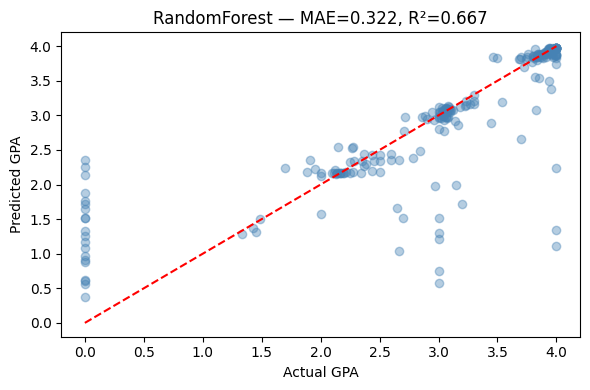

In [17]:
y_pred_best = gpa_model.predict(X_te)
plt.figure(figsize=(6, 4))
plt.scatter(y_te, y_pred_best, alpha=0.4, color='steelblue')
plt.plot([0, 4], [0, 4], 'r--', lw=1.5)
plt.xlabel('Actual GPA')
plt.ylabel('Predicted GPA')
plt.title(f'{best_name} — MAE={mae:.3f}, R²={r2:.3f}')
plt.tight_layout()
plt.show()



At-Risk Classifier

In [19]:
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(
    X, y_risk, test_size=0.2, random_state=42, stratify=y_risk
)

n_safe = (y_tr2 == 0).sum()
n_risk = (y_tr2 == 1).sum()
scale  = round(n_safe / n_risk, 2)
print(f"Class ratio → safe: {n_safe}, at-risk: {n_risk}, scale: {scale}")

sw = y_tr2.map({0: 1.0, 1: scale}).values

risk_model = GradientBoostingClassifier(
    n_estimators=400, learning_rate=0.02,
    max_depth=4, subsample=0.8,
    min_samples_leaf=3, random_state=42
)
risk_model.fit(X_tr2, y_tr2, sample_weight=sw)


Class ratio → safe: 755, at-risk: 113, scale: 6.68


GradientBoostingClassifier(learning_rate=0.02, max_depth=4, min_samples_leaf=3,
                           n_estimators=400, random_state=42, subsample=0.8)

In [20]:
y_proba  = risk_model.predict_proba(X_te2)[:, 1]
threshold = 0.35
y_pred2  = (y_proba >= threshold).astype(int)

print(f"\nAt-Risk Results (threshold={threshold}):")
print(classification_report(y_te2, y_pred2, target_names=['Safe', 'At Risk']))




At-Risk Results (threshold=0.35):
              precision    recall  f1-score   support

        Safe       0.99      0.92      0.96       190
     At Risk       0.64      0.96      0.77        28

    accuracy                           0.93       218
   macro avg       0.82      0.94      0.86       218
weighted avg       0.95      0.93      0.93       218



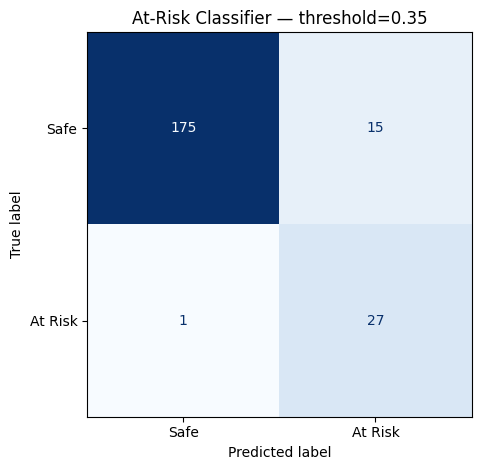

In [21]:
ConfusionMatrixDisplay(
    confusion_matrix(y_te2, y_pred2),
    display_labels=['Safe', 'At Risk']
).plot(cmap='Blues', colorbar=False)
plt.title(f'At-Risk Classifier — threshold={threshold}')
plt.tight_layout()
plt.show()

Feature Importance

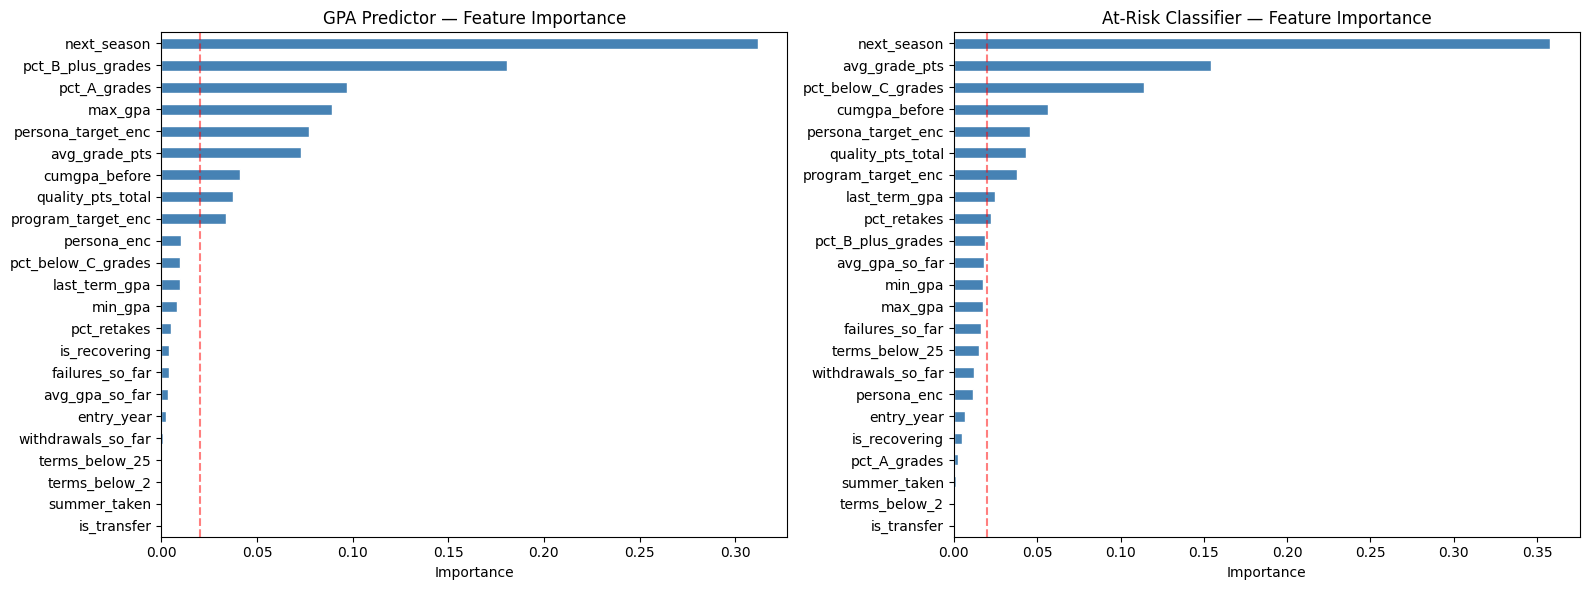

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, model, title in zip(
    axes,
    [gpa_model if hasattr(gpa_model, 'feature_importances_') else candidates['GradBoosting'],
     risk_model],
    ['GPA Predictor — Feature Importance', 'At-Risk Classifier — Feature Importance']
):
    imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
    imp.plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
    ax.set_title(title)
    ax.axvline(x=0.02, color='red', linestyle='--', alpha=0.5, label='threshold 0.02')
    ax.set_xlabel('Importance')

plt.tight_layout()
plt.show()


Save Models

In [23]:
os.makedirs('models', exist_ok=True)

def save_model(model, name: str, metrics: dict = None) -> str:
    timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    path = f'models/{name}_{timestamp}.pkl'
    bundle = {
        'model':    model,
        'name':     name,
        'saved_at': timestamp,
        'metrics':  metrics or {},
        'features': FEATURES,
        'threshold': 0.35 if 'risk' in name else None,
        'encoders': {
            'gender':            le_gender,
            'persona':           le_persona,
            'program_mean_gpa':  program_mean_gpa.to_dict(),
            'persona_mean_gpa':  persona_mean_gpa.to_dict(),
        },
    }
    joblib.dump(bundle, path)
    print(f"{path}  ({os.path.getsize(path)/1024:.1f} KB)")
    return path

path_gpa  = save_model(gpa_model,  'gpa_predictor',
                        {'MAE': round(mae,3), 'R2': round(r2,3), 'model': best_name})
path_risk = save_model(risk_model, 'risk_classifier',
                        {'threshold': 0.35, 'scale_pos': scale})



💾 models/gpa_predictor_20260502_153700.pkl  (1055.6 KB)
💾 models/risk_classifier_20260502_153701.pkl  (805.8 KB)


Load & Predict

In [31]:
def load_model(path: str):
    b = joblib.load(path)
    print(f"{b['name']} | saved: {b['saved_at']} | metrics: {b['metrics']}")
    return b

def predict_next_gpa(bundle_path: str, student: dict) -> dict:
    """

    student dict :
    {
        'gender':            'Male',
        'persona':           'solid_b',
        'program':           'Software Development',
        'entry_year':        2023,
        'is_transfer':       0,
        'semester_number':   3,
        'cumgpa_before':     2.9,
        'last_term_gpa':     2.7,
        'avg_gpa_so_far':    2.85,
        'min_gpa':           2.5,
        'max_gpa':           3.2,
        'gpa_std':           0.25,
        'gpa_trend':         -0.1,
        'recent_trend':      0.1,
        'terms_below_2':     0,
        'terms_below_25':    1,
        'is_recovering':     1,
        'credits_so_far':    51,
        'withdrawals_so_far':0,
        'failures_so_far':   0,
        'pct_A_grades':      0.15,
        'pct_B_plus_grades': 0.55,
        'pct_below_C_grades':0.0,
        'pct_retakes':       0.0,
        'pct_lab_courses':   0.2,
        'avg_grade_pts':     2.9,
        'quality_pts_total': 420.0,
        'summer_taken':      0,
        'next_season':       1,
    }
    """
    b   = joblib.load(bundle_path)
    enc = b['encoders']

    # encode الـ categorical
    student['gender_enc']         = enc['gender'].transform([student['gender']])[0]
    student['persona_enc']        = enc['persona'].transform([student['persona']])[0]
    student['program_target_enc'] = enc['program_mean_gpa'].get(student['program'], 2.887)
    student['persona_target_enc'] = enc['persona_mean_gpa'].get(student['persona'], 2.887)

    row  = pd.DataFrame([{f: student[f] for f in b['features']}])
    pred = b['model'].predict(row)[0]
    pred = round(float(np.clip(pred, 0, 4)), 3)

    return {
        'predicted_gpa': pred,
        'at_risk':        pred < 2.0,
        'status':         'AT RISK' if pred < 2.0 else 'Safe',
        'confidence':     'High' if abs(pred - 2.0) > 0.5 else 'Medium',
    }



TESTING

In [32]:
bundle = load_model(path_gpa)

result = predict_next_gpa(path_gpa, {
    'gender': 'Male', 'persona': 'solid_b',
    'program': 'Software Development', 'entry_year': 2023,
    'is_transfer': 0, 'semester_number': 3,
    'cumgpa_before': 2.9, 'last_term_gpa': 2.7,
    'avg_gpa_so_far': 2.85, 'min_gpa': 2.5, 'max_gpa': 3.2,
    'gpa_std': 0.25, 'gpa_trend': -0.1, 'recent_trend': 0.1,
    'terms_below_2': 0, 'terms_below_25': 1, 'is_recovering': 1,
    'credits_so_far': 51, 'withdrawals_so_far': 0, 'failures_so_far': 0,
    'pct_A_grades': 0.15, 'pct_B_plus_grades': 0.55,
    'pct_below_C_grades': 0.0, 'pct_retakes': 0.0,
    'pct_lab_courses': 0.2, 'avg_grade_pts': 2.9,
    'quality_pts_total': 420.0, 'summer_taken': 0, 'next_season': 1,
})
print(f"\nResult: {result}")



gpa_predictor | saved: 20260502_153700 | metrics: {'MAE': 0.322, 'R2': 0.667, 'model': 'RandomForest'}

Result: {'predicted_gpa': 3.145, 'at_risk': False, 'status': 'Safe', 'confidence': 'High'}


In [26]:
from google.colab import files as colab_files

for pkl in glob.glob('models/*.pkl'):
    colab_files.download(pkl)
    print(f" {pkl}")

print("\n Done! All model files downloaded.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

models/risk_classifier_20260502_153701.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

models/gpa_predictor_20260502_153700.pkl

 Done! All model files downloaded.


In [28]:
experiment = {
    "model": name,
    "mae": mae,
    "r2": r2,
    "features": FEATURES,
    "timestamp": datetime.now()
}

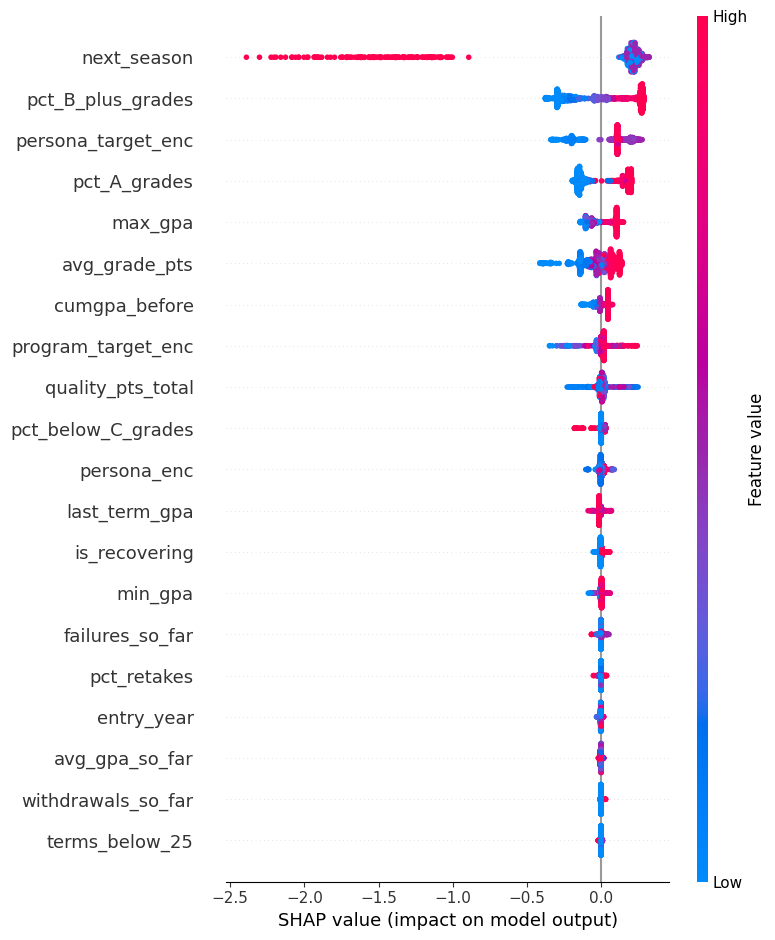

In [27]:
import shap

explainer = shap.TreeExplainer(gpa_model)
shap_values = explainer.shap_values(X)
shap.summary_plot(shap_values, X)